<a href="https://colab.research.google.com/github/triprasetyaningsih7700-max/index-html/blob/main/TriPrasetya_RegresiLinear_pemsi_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [ ]:
df = pd.DataFrame([[153,63], [174,81], [136,56], [186,91], [128,47], [136,57], [179,76], [163,72], [131,48]])
df.columns = ["x", "y"]

In [ ]:
df.corr()

,x,y
x,1.000000,0.976058
y,0.976058,1.000000


In [ ]:
x_train = df['x'].values[:,np.newaxis]
x_train = df['y'].values

x_train

array([63, 81, 56, 91, 47, 57, 76, 72, 48])

In [ ]:
y_train

NameError: name 'y_train' is not defined

In [ ]:
lm = LinearRegression()
lm.fit(x_train, y_train)

In [ ]:
x_test = [[170], [160], [180], [171], [150]]
p = lm.predict(x_test)
p

In [ ]:
print("Coefficient :", lm.coef_)
print("Intercept :", lm.intercept_)

AttributeError: 'LinearRegression' object has no attribute 'coef_'

In [ ]:
pb = lm.predict(x_train)
dfc = pd.DataFrame({'x': df['x'], 'y':pb})
plt.scatter(df['x'], dfc['y'], color='magenta', linewidth=1)
plt.xlabel('Nilai X')
plt.ylabel('Nilai Y')
plt.show

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import  root_mean_squared_error, r2_score

In [ ]:
df = pd.read_csv("botak.csv")
df

,umur,jenis_kelamin,pekerjaan,provinsi,gaji,is_menikah,is_keturunan,berat,tinggi,sampo,is_merokok,pendidikan,botak_prob
0,42.0,Laki-laki,PNS,Padang,7.864005e+06,0,0.0,61.928685,152.174164,Deadbuoy,1,S1,0.487655
1,33.0,Laki-laki,Pegawai swasta,Palangkaraya,6.492662e+06,0,0.0,49.374507,152.822969,Moonsilk,1,SMA,0.297270
2,59.0,Laki-laki,Freelance,Serang,8.086303e+06,1,0.0,59.072807,159.911047,Merpati,1,S1,0.467848
3,38.0,Laki-laki,Pegawai swasta,Gorontalo,1.147321e+07,0,1.0,68.338014,162.558997,Moonsilk,0,S1,0.616418
4,33.0,Perempuan,Freelance,Tanjungselor,1.475942e+07,0,0.0,53.769996,154.579510,Pantone,1,S2,0.115439
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7986,31.0,Laki-laki,Pegawai swasta,Padang,2.911963e+07,0,0.0,83.272785,176.020857,Merpati,0,SMA,0.241525
7987,40.0,Perempuan,Pegawai swasta,Banjarmasin,8.955173e+06,0,0.0,61.634474,161.780773,Deadbuoy,0,S1,0.140971
7988,43.0,Perempuan,PNS,Mataram,4.022652e+06,0,0.0,50.525031,152.461656,Shoulder & Head,1,S1,0.364456
7989,29.0,Laki-laki,Pegawai swasta,Serang,5.801753e+06,0,0.0,47.175270,152.749709,NaN,1,SMA,0.248910


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7991 entries, 0 to 7990
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   umur           7991 non-null   float64
 1   jenis_kelamin  7982 non-null   object 
 2   pekerjaan      7924 non-null   object 
 3   provinsi       7991 non-null   object 
 4   gaji           7968 non-null   float64
 5   is_menikah     7991 non-null   int64  
 6   is_keturunan   7976 non-null   float64
 7   berat          7952 non-null   float64
 8   tinggi         7991 non-null   float64
 9   sampo          7934 non-null   object 
 10  is_merokok     7991 non-null   int64  
 11  pendidikan     7991 non-null   object 
 12  botak_prob     7991 non-null   float64
dtypes: float64(6), int64(2), object(5)
memory usage: 811.7+ KB


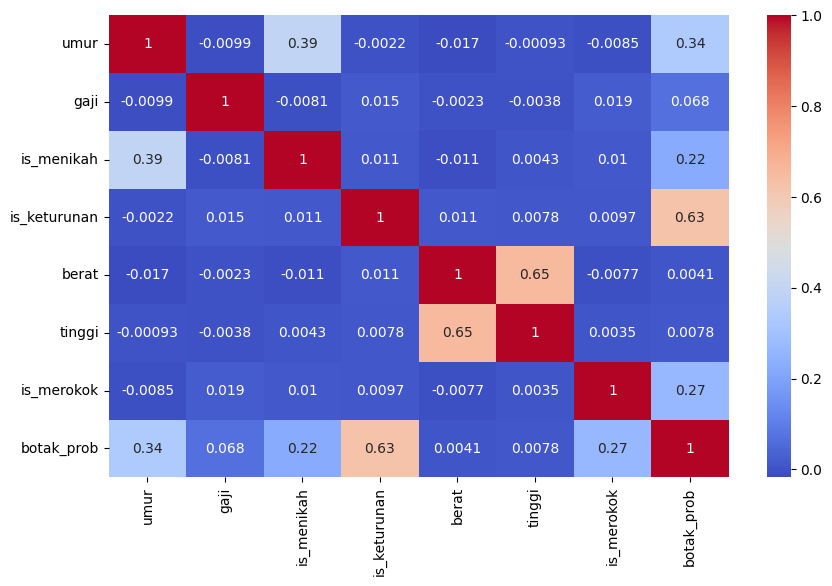

In [ ]:
import seaborn as sns

num_df = df.select_dtypes(include=['int64', 'float64'])

plt.figure(figsize=(10,6))
sns.heatmap(num_df.corr(), annot=True, cmap="coolwarm")
plt.show()

In [ ]:
db = df.dropna(subset=["umur", "gaji", "tinggi", "berat", "botak_prob"])

x = db[["umur", "gaji", "tinggi", "berat"]]
y = db[["botak_prob"]]

In [ ]:
from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size=0.2, random_state=0)

In [ ]:
model = LinearRegression()
model.fit(x_train, y_train)

LinearRegression()

In [ ]:
y_pred = model.predict(x_test)

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

print("Koefisien :", model.coef_)
print("Intercept :", model.intercept_)
print("MSE :", mean_squared_error(y_test, y_pred))
print("R2 Score :", r2_score(y_test, y_pred))

Koefisien : [[6.62511272e-03 2.82405850e-09 1.98134987e-05 2.24672288e-04]]
Intercept : [0.09067105]
MSE : 0.03177222988707976
R2 Score : 0.10923976549414827


In [ ]:
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha= 0.5)
plt.xlabel("Nilai Asli y_test")
plt.ylabel("Nilia prediksi y_pred")